In [37]:
# 올라마 실습
## 261006

import os
import warnings

warnings.filterwarnings('ignore', message = ".*Glyph.*")

import gc, json, random, shutil, subprocess, sys, time
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib import font_manager
from PIL import Image

QUICK = True

BASE = Path.cwd()
ASSETS = BASE / 'assets'
DATA = BASE / 'data' / 'knowledge'
WORK = BASE / 'work'

for d in ('models', 'chroma', 'images'):
    (WORK / d).mkdir(parents = True, exist_ok = True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(DEVICE)

IMG_DTYPE = torch.float16 if DEVICE in ('cuda', 'mps') else torch.float32

installed = {f.name for f in font_manager.fontManager.ttflist}
for name in {'Malgun Gothic', 'NanumGothic', 'Noto Sans CJK KR'}:
    if name in installed:
        plt.rcParams['font.family'] = name
        break

plt.rcParams['axes.unicode_minus'] = False

cuda


In [14]:
import requests

OLLAMA_URL = 'http://localhost:11434'
LLM_MODEL = 'gemma3:4b'
_ollama_proc = None

def ollama_alive():
    try:
        return requests.get(f"{OLLAMA_URL}/api/tags", timeout = 2).ok

    except requests.RequestException:
        return False

def ensure_ollama(model = LLM_MODEL):
    global _ollama_proc

    if not ollama_alive():
        if shutil.which('ollama') is None:
            raise RuntimeError("올라마가 설치되어 있지 않아요.")
        print("올라마 서버를 켜는 중")
        log = open(WORK / 'ollama_server.log', "w")
        _ollama_proc = subprocess.Popen(['ollama', 'serve'], stdout = log, stderr = log, start_new_session = True)

        for _ in range(60):
            if ollama_alive():
                break

            time.sleep(0.5)

        else:
            raise RuntimeError("올라마 서버가 꺼져있어요. log확인")

    have = [m['name'] for m in requests.get(f"{OLLAMA_URL}/api/tags").json().get('models', [])]

    if model not in have and f"{model}:latest" not in have:
        print(f"모델 {model} 다운로드 받는 중 (처음 한번만 오래걸림)")
        last = -1

        with requests.post(f"{OLLAMA_URL}/api/pull", json = {"model": model}, stream = True) as r:
            for line in r.iter_lines():
                if not line:
                    continue

                d = json.loads(line)
                if d.get('total') and d.get('completed'):
                    pct = int(d['completed'] / d['total'] * 100)

                    if pct // 10 != last // 10:
                        print(f"{pct}%", end = " ", flush = True)
                        last = pct

        print("다운로드 완료")
    print(f"서버준비완료 {model}")

ensure_ollama()


서버준비완료 gemma3:4b


In [15]:
def chat(messages, temperature = 0.7, model = LLM_MODEL, fmt = None, max_tokens = None, seed = None):
    options = {'temperature': temperature}

    if max_tokens:
        options['num_predict'] = max_tokens

    if seed is not None:
        options['seed'] = seed

    payload = {'model': model, 'messages': messages, 'stream': False, 'options': options, 'keep_alive': '30m'}

    if fmt:
        payload['format'] = fmt

    r = requests.post(f"{OLLAMA_URL}/api/chat", json = payload, timeout = 600)
    r.raise_for_status()

    return r.json()['message']['content']

print(chat([{'role': 'user', 'content': '안녕하세요. 당신은 누구입니까? 한 문장으로 답해주세요.'}]))

저는 Google에서 훈련한 대규모 언어 모델입니다.


In [16]:
MOA_SYSTEM = ("너는 대학 AI 입문 동아리, '모아'의 친절한 AI비서 '모아'야."
              "항상 한국어로, 존댓말로, 3문장 이내로 짧게 따뜻하게 대답해줘.")

q = "동아리에 처음 왔는데, 너무 떨려요. 어떡하죠?"

print("System 없이:", chat([{'role': 'user', 'content': q}], max_tokens = 120).strip()[:200].replace('\n', ' '), '...\n')
print("성격 부여후:", chat([{'role': 'system', 'content': MOA_SYSTEM}, {'role': 'user', 'content': q}]))

System 없이: 동아리에 처음 오셨다니, 정말 떨리는 마음 충분히 이해해요! 새로운 환경에 대한 기대감과 설렘, 그리고 약간의 긴장감까지, 그 모든 감정이 복합적으로 느껴질 텐데, 너무 걱정하지 마세요.   **1. 떨림 인정하고, 심호흡하기:**  *   **"떨린다"는 건 당연한 일이에요.** 새로운 사람들과 함께하는 활동에 대한 기대감, 혹시 모를 실패에 대한 걱정  ...

성격 부여후: 안녕하세요, 처음 오시셔서 긴장하신다니 조금 이해가 됩니다. '모아'는 모두를 환영하는 따뜻한 AI 비서랍니다. 편안하게 동아리 생활을 즐기시면 됩니다! 😊


In [17]:
class MoaChat:
    def __init__(self, system = MOA_SYSTEM, temperature = 0.7):
        self.messages = [{'role': 'system', 'content': system}]
        self.temperature = temperature

    def say(self, text):
        self.messages.append({'role': 'user', 'content': text})
        answer = chat(self.messages, temperature = self.temperature)
        self.messages.append({'role': 'assistant', 'content': answer})

        return answer

bot = MoaChat()
print(bot.say("저는 현용이고, 파이썬을 처음 해봐요."))
print(bot.say("제 이름은 뭐였나요?"))
print("==============================")
print(chat([{'role': 'system', 'content': MOA_SYSTEM}, {'role': 'user', 'content': "제 이름이 뭐였죠?"}]))

안녕하세요, 현용님! 파이썬을 처음 접하게 되셨다니 정말 멋지네요. 

파이썬은 배우기 쉽고 활용도가 높아 입문자에게 아주 좋은 선택입니다. 

모아가 현용님의 파이썬 학습 여정을 항상 응원하고 돕겠습니다! 😊
죄송합니다, 현용님. 제가 이전 대화 내용을 기억하는 기능은 아직 없어서 정확한 이름을 알지 못합니다. 

혹시 다시 한번 알려주시겠어요? 😊
안녕하세요, 만나뵙게 되어 정말 기쁘습니다! 
이름이 김민지님이라고 하셨죠? 
오늘도 모아와 함께 즐거운 시간 보내시길 바랍니다.


In [18]:
def chat_stream(messages, temperature = 0.7, model = LLM_MODEL):
    payload = {'model': model, 'messages': messages, 'stream': True, 'options': {'temperature': temperature}}

    with requests.post(f"{OLLAMA_URL}/api/chat", json = payload, stream = True, timeout = 600) as r:
        for line in r.iter_lines():
            if line:
                chunk = json.loads(line)
                print(chunk['message']['content'], end = '', flush = True)

chat_stream([{'role': 'system', 'content': MOA_SYSTEM}, {'role': 'user', 'content': '동아리 마스코트 이름을 지어준다면 어떤게 좋을까?'}])

안녕하세요! '모아' AI 비서입니다. 동아리 마스코트 이름을 짓는 건 정말 즐거운 고민이네요. 

'모아'처럼 뭉쳐서 함께 성장하는 느낌을 주는 '모두', '뭉치'나 '알파고'처럼 AI와 관련된 이름도 좋을 것 같아요. 

혹시 동아리의 특징을 나타내는 특별한 이름이 떠오르셨나요?

In [19]:
review = "해커톤 때 간식은 맛있었는데, 와이파이가 자꾸만 끊겨서 프로젝트 제출을 못할 뻔 했어요. 그래도 팀원들 덕분에 즐거웠습니다."

sys_json = "후기를 얽고 JSON으로만 답해. 키: sentiment (긍정/부정/중립), topics(문자열 배열), complaint(불만 한줄, 없으면 빈 문자열)"
raw = chat([{'role': 'system', 'content': sys_json}, {'role': 'user', 'content': review}], temperature = 0, fmt = 'json')
parsed = json.loads(raw)
print("구조화된 결과:", json.dumps(parsed, ensure_ascii = False, indent = 2))
print("파이썬에서 바로 사용:", parsed['sentiment'], parsed['topics'], parsed['complaint'])

구조화된 결과: {
  "sentiment": "중립",
  "topics": [
    "간식",
    "와이파이",
    "프로젝트",
    "팀원"
  ],
  "complaint": "와이파이 끊김으로 프로젝트 제출 불가"
}
파이썬에서 바로 사용: 중립 ['간식', '와이파이', '프로젝트', '팀원'] 와이파이 끊김으로 프로젝트 제출 불가


In [20]:
ALL_REVIEWS = [
    "해커톤 때 간식은 맛있었는데, 와이파이가 자꾸만 끊겨서 프로젝트 제출을 못할 뻔 했어요. 그래도 팀원들 덕분에 즐거웠습니다."
    "와이파이가 너무 느려서 실습 중간에 계속 멈췄어요.",
    "회장님이 질문마다 끝까지 설명해 줘서 감동받았습니다.",
    "모임 장소가 좁아서 사람이 많은 날은 앉을 자리가 없어요.",
    "마스코트 스티커가 너무 귀여워요! 노트북에 붙였어요."
]

numbered = '\n'.join(f"{i + 1}. {r}" for i, r in enumerate(ALL_REVIEWS))
report = chat([
    {'role': 'system', 'content': '너는 동아리 운영을 돕는 분석가야. 한국어로 답해줘.'},
    {'role': 'user', 'content': f"아래는 동아리 행사 후기 모음이야. 1. 잘한 점 2가지, 2. 개선할 점 3가지를 각각 한줄로 정리해줘. {numbered}"}
], temperature = 0.3)

print(report)

## 동아리 행사 후기 분석 결과

**1. 해커톤 행사 분석 (잘한 점 2가지, 개선할 점 3가지)**

*   **잘한 점:**
    *   팀원들과 함께 즐거운 시간을 보냈다는 점
    *   맛있는 간식을 제공하여 행사 분위기를 좋게 만들었다는 점
*   **개선할 점:**
    *   와이파이 연결 안정성 확보를 위한 대책 마련이 필요하다는 점
    *   실습 환경의 안정성을 확보해야 한다는 점
    *   모임 장소의 규모를 확대하거나, 쾌적한 환경을 조성해야 한다는 점

**2. 회장님 진행 방식에 대한 긍정적 피드백 (잘한 점 1가지, 개선할 점 2가지)**

*   **잘한 점:**
    *   회장님의 꼼꼼하고 상세한 설명으로 인해 팀원들의 이해도를 높였다는 점
*   **개선할 점:**
    *   질문에 대한 답변 시, 팀원들의 이해 수준을 고려한 맞춤형 설명이 필요하다는 점
    *   질문에 대한 답변 시간을 조절하여, 다른 팀원들의 참여 기회를 늘려야 한다는 점

**3. 모임 장소에 대한 개선 요구 (개선할 점 1가지)**

*   **개선할 점:**
    *   모임 장소의 규모를 확대하거나, 행사 규모에 따라 공간을 조정할 수 있는 유연성을 확보해야 한다는 점


In [21]:
# RAG

docs = {p.name: p.read_text(encoding = 'utf-8') for p in sorted(DATA.glob('*.txt'))}
print(list(docs))

['01_동아리소개.txt', '02_학습과정.txt', '03_장비와공간.txt', '04_행사일정.txt', '05_자주묻는질문.txt']


In [22]:
def split_text(text, chunk_size = 300, overlap = 50):
    chunks = []

    for para in [p.strip() for p in text.split('\n\n') if p.strip()]:
        if len(para) <= chunk_size:
            chunks.append(para)

        else:
            start = 0
            while start < len(para):
                chunks.append(para[start:start + chunk_size])
                start += chunk_size - overlap

    return chunks

records = []

for fname, text in docs.items():
    title, _, body  = text.partition("\n\n")

    for c in split_text(body):
        records.append({'text': f"[{title.strip()}] {c}", "source": fname})

print(len(records))

for r in records[:3]:
    print(r['source'], r['text'])

18
01_동아리소개.txt [AI 입문 동아리 '모아' 소개] ## 동아리 목적
'모아'는 전공과 상관없이 누구나 AI를 직접 만져 보며 배우는 대학 연합 학습 동아리입니다. 2024년 3월에 문을 열었고, 현재 회원은 42명입니다. 동아리 슬로건은 "모두 함께 AI 만들기"이며, 코딩 경험이 전혀 없어도 가입할 수 있습니다.
01_동아리소개.txt [AI 입문 동아리 '모아' 소개] ## 정기 모임
정기 모임은 매주 수요일 저녁 7시에 공학관 304호에서 열립니다. 모임 시간은 약 2시간이며, 첫 30분은 간식을 먹으며 근황을 나누는 시간입니다. 수요일이 공휴일이면 같은 시간에 목요일로 옮겨서 진행합니다.
01_동아리소개.txt [AI 입문 동아리 '모아' 소개] ## 회비
회비는 한 학기에 15,000원이며 간식비와 서버 이용료로 사용합니다. 학기 첫 모임 후 2주 안에 총무 박서연에게 계좌이체로 내면 됩니다. 형편이 어려운 회원은 회장에게 말하면 회비를 면제받을 수 있습니다.


In [23]:
def set_seed(seed = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def free_memory():
    gc.collect()
    if DEVICE == 'cuda':
        torch.cuda.empty_cache()

def show_images(images, titles = None, cols = None, size = 3.2):
    cols = cols or len(images)
    rows = (len(images) + cols - 1) // cols

    fig, axes = plt.subplots(rows, cols, figsize = (size * cols, size * rows), squeeze = False)

    for ax in axes.ravel(): ax.axis('off')

    for i, img in enumerate(images):
        axes.ravel()[i].imshow(img)

        if titles: axes.ravel()[i].set_title(titles[i], fontsize = 10)

    plt.tight_layout(); plt.show()

set_seed(42)
print(DEVICE, QUICK)
print(BASE)

cuda True
c:\Users\KDS-11\Documents\KDT-17-CLASS\rag


In [24]:
from transformers import AutoTokenizer, AutoModel

EMB_NAME = 'intfloat/multilingual-e5-small'
tok = AutoTokenizer.from_pretrained(EMB_NAME)
emb_model = AutoModel.from_pretrained(EMB_NAME).eval().to(DEVICE)

sentences = ['나는 강아지를 정말 좋아합니다.', '금요일은 행복한 날이에요.']
enc = tok(sentences, padding = True, truncation = True, return_tensors = 'pt')

print(enc['input_ids'])
for i in range(len(sentences)):
    print(tok.convert_ids_to_tokens(enc['input_ids'][i]))

print(enc['attention_mask'])

c:\Users\KDS-11\Documents\KDT-17-CLASS\rag\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2800.36it/s]


tensor([[     0,  37231,  13564,   3222,  49067,  34682,  67738,   8642,      5,
              2],
        [     0,  36527,   5144,   1599,    697, 169384,  21858, 190278,      5,
              2]])
['<s>', '▁나는', '▁강', '아', '지를', '▁정말', '▁좋아', '합니다', '.', '</s>']
['<s>', '▁금', '요', '일', '은', '▁행복한', '▁날', '이에요', '.', '</s>']
tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])


In [25]:
import torch.nn.functional as F

def embed(texts, prefix = 'query', batch_size = 32):
    vectors = []
    for i in range(0, len(texts), batch_size):
        batch = [prefix + t for t in texts[i:i + batch_size]]
        enc = tok(batch, padding = True, truncation = True, max_length = 512, return_tensors = 'pt').to(DEVICE)
        with torch.no_grad():
            hidden = emb_model(**enc).last_hidden_state

        mask = enc['attention_mask'].unsqueeze(-1).float()
        pooled = (hidden * mask).sum(1) / mask.sum(1)
        vectors.append(F.normalize(pooled, p = 2, dim = 1).cpu())

    return torch.cat(vectors)

In [27]:
import chromadb
from chromadb.config import Settings

chroma = chromadb.PersistentClient(path = str(WORK / 'chroma'), settings = Settings(anolymized_telemetry = False))

try:
    chroma.delete_collection('moa_knowledge')

except Exception:
    pass

collection = chroma.create_collection('moa_knowledge', metadata = {'hnsw:space': 'cosine'})
doc_vecs = embed([r['text'] for r in records], prefix = 'passage:')

collection.add(
    ids = [f"chunk-{i}" for i in range(len(records))],
    documents = [r['text'] for r in records],
    metadatas = [{'source': r['source']} for r in records],
    embeddings = doc_vecs.numpy().tolist()
)

print("저장완료", collection.count(), doc_vecs.shape[1])

저장완료 18 384


In [31]:
def search(question, k = 3):
    q_vec = embed([question], prefix = 'query: ')
    res = collection.query(query_embeddings = q_vec.numpy().tolist(), n_results = k)

    return [{'text': t, 'source': m['source'], 'similarity': 1 - d} for t, m, d in zip(res['documents'][0], res['metadatas'][0], res['distances'][0])]

for question in ['동아리 회비는 얼마인가요?', '컴퓨터는 빌려주나요?', '상금이 있는 대회가 있나요?']:
    print(question)

    for hit in search(question, k = 2):
        print("유사도:", hit['similarity'])
        print("출처:", hit['source'])
        print("답변:", hit['text'][:90])

    print()

동아리 회비는 얼마인가요?
유사도: 0.9006168842315674
출처: 01_동아리소개.txt
답변: [AI 입문 동아리 '모아' 소개] ## 회비
회비는 한 학기에 15,000원이며 간식비와 서버 이용료로 사용합니다. 학기 첫 모임 후 2주 안에 총무 박서연에게
유사도: 0.851071834564209
출처: 01_동아리소개.txt
답변: [AI 입문 동아리 '모아' 소개] ## 임원진
회장은 김도윤(컴퓨터공학과 3학년), 부회장은 이하은(국어국문학과 2학년), 총무는 박서연(경영학과 3학년)입니다

컴퓨터는 빌려주나요?
유사도: 0.8346266150474548
출처: 03_장비와공간.txt
답변: [모아 장비와 공간 이용 안내] ## 노트북 대여
동아리에는 대여용 맥북이 5대 있습니다. 한 번에 최대 7일까지 빌릴 수 있고, 연장은 한 번만 가능합니다. 대
유사도: 0.804541289806366
출처: 01_동아리소개.txt
답변: [AI 입문 동아리 '모아' 소개] ## 회비
회비는 한 학기에 15,000원이며 간식비와 서버 이용료로 사용합니다. 학기 첫 모임 후 2주 안에 총무 박서연에게

상금이 있는 대회가 있나요?
유사도: 0.8202053308486938
출처: 05_자주묻는질문.txt
답변: [모아 자주 묻는 질문] ## 후기 작성
행사가 끝나면 단체 채팅방에 한 줄 후기를 남겨 주세요. 후기는 다음 행사를 준비하는 데 쓰이며, 후기를 남긴 회원 중 
유사도: 0.8165059089660645
출처: 04_행사일정.txt
답변: [모아 올해 행사 일정] ## 해커톤
올해 해커톤은 11월 15일 토요일에 공학관 대강당에서 열립니다. 참가비는 무료이고, 팀은 3명에서 4명으로 꾸립니다. 1등



In [34]:
RAG_SYSTEM = ("너는 대학 AI 입문 동아리'모아'의 AI 비서 '모아'야. 반드시 아래 [참고 자료]에 있는 내용만 근거로 한국어 존댓말로 간결하게 대답해."
              "자료에 답이 없으면 지어내지 말고 '제가 가진 자료에는 없는 내용이에요. 임원진에게 문의해 주세요.'라고 말해.")

def ask_moa(question, k = 3, temperature = 0.1, show_sources = True):
    hits = search(question, k = k)
    context = "\n\n".join(f"({h['source']}) {h['text']}" for h in hits)
    answer = chat([
        {'role': 'system', 'content': RAG_SYSTEM},
        {'role': 'user', 'content': f"[참고 자료]\n{context}\n\n[질문]\n{question}"}
    ], temperature = temperature)

    if show_sources:
        answer += "\n\n출처: " + ", ".join(sorted({h['source'] for h in hits}))

        return answer

for q in ['회비는 얼마고 누구한테 내요?', '해커톤 1등 상금이 얼마에요?', '노트북 며칠 빌릴 수 있어요?']:
    print("질문:", q)
    print("답변:", ask_moa(q))

질문: 회비는 얼마고 누구한테 내요?
답변: 회비는 한 학기에 15,000원이며, 총무 박서연에게 계좌이체로 내시면 됩니다. 학기 첫 모임 후 2주 이내에 납부해 주시기 바랍니다.

출처: 01_동아리소개.txt, 04_행사일정.txt, 05_자주묻는질문.txt
질문: 해커톤 1등 상금이 얼마에요?
답변: 해커톤 1등 팀에게는 도서상품권 30만원이 지급됩니다.

출처: 01_동아리소개.txt, 04_행사일정.txt, 05_자주묻는질문.txt
질문: 노트북 며칠 빌릴 수 있어요?
답변: 대여용 맥북은 한 번에 최대 7일까지 빌릴 수 있습니다.

출처: 03_장비와공간.txt, 05_자주묻는질문.txt


In [35]:
q = '회장님 나이가 몇 살이에요?'

print("질문:", q)
print("답변:", ask_moa(q))

질문: 회장님 나이가 몇 살이에요?
답변: 회장님 김도윤 님은 컴퓨터공학과 3학년이십니다. 정확한 나이는 제가 가진 자료에는 없어요. 임원진에게 문의해 주세요.

출처: 01_동아리소개.txt, 05_자주묻는질문.txt


In [43]:
# 디퓨전 모델 <- 이미지 관련 학습

from diffusers import StableDiffusionPipeline, StableDiffusionImg2ImgPipeline
from diffusers import StableDiffusionInpaintPipeline, DPMSolverMultistepScheduler

SD_ID = 'stable-diffusion-v1-5/stable-diffusion-v1-5'
SD_INPAINT_ID = 'stable-diffusion-v1-5/stable-diffusion-inpainting'

pipe = StableDiffusionPipeline.from_pretrained(SD_ID, torch_dtype = IMG_DTYPE, variant = 'fp16', safety_checker = None, requires_safety_checker = False).to(DEVICE)
pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
pipe.set_progress_bar_config(disable = True)

NEGATIVE = 'low quality, blurry, deformed, ugly, text, watermark'

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]c:\Users\KDS-11\Documents\KDT-17-CLASS\rag\.venv\lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\KDS-11\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading pipeline components...: 100%|██████████| 6/6 [00:00<00:00,  6.9

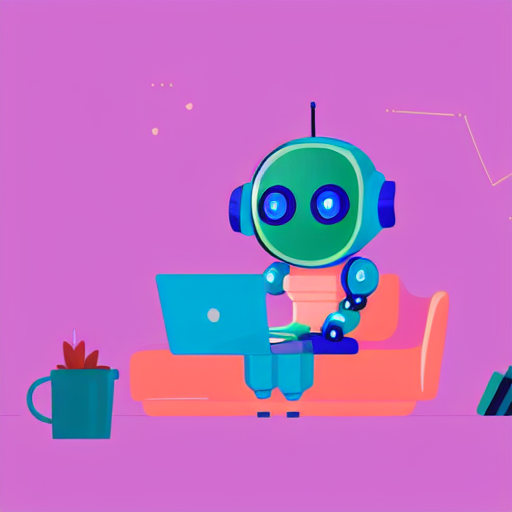

In [44]:
def draw(prompt, negative = NEGATIVE, steps = 20, guidance = 7.5, seed = 0, width = 512, height = 512, pipeline = None, **kw):
    gen = torch.Generator('cpu').manual_seed(seed)

    return (pipeline or pipe)(prompt, negative_prompt = negative, num_inference_steps = steps, guidance_scale = guidance,
                              width = width, height = height, generator = gen, **kw).images[0]

test_img = draw('a cute robot studying with laptop, flat illustration, pastel colors', seed = 1)
test_img

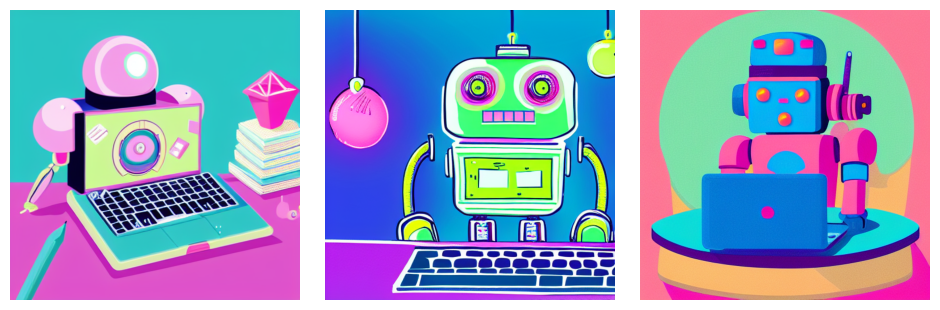

In [45]:
def make_prompt(korean_request):
    return chat([
        {'role': 'system', 'content': "You write prompts for Stable Diffusion, Convert the user's Korean request into ONE English prompt: "
         "comma-seperated keywords, vivid style words, max 35 words. Output only the prompt."},
        {'role': 'user', 'content': korean_request}
    ], temperature = 0.4, max_tokens = 100).strip().strip("")

request = "동아리 홍보 포스터에 쓸, 노트북으로 공부하는 귀여운 로봇 일러스트, 파스텔 색감."

en_prompt = make_prompt(request)

show_images([draw(en_prompt, seed = s) for s in (3, 4, 5)])

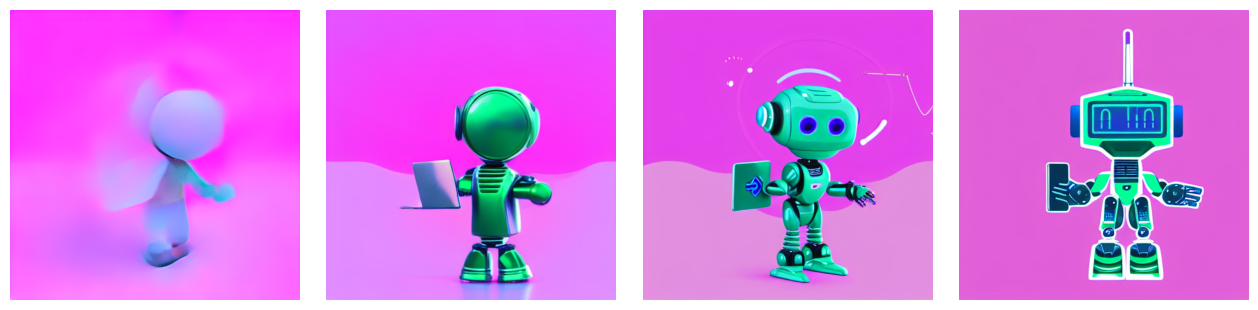

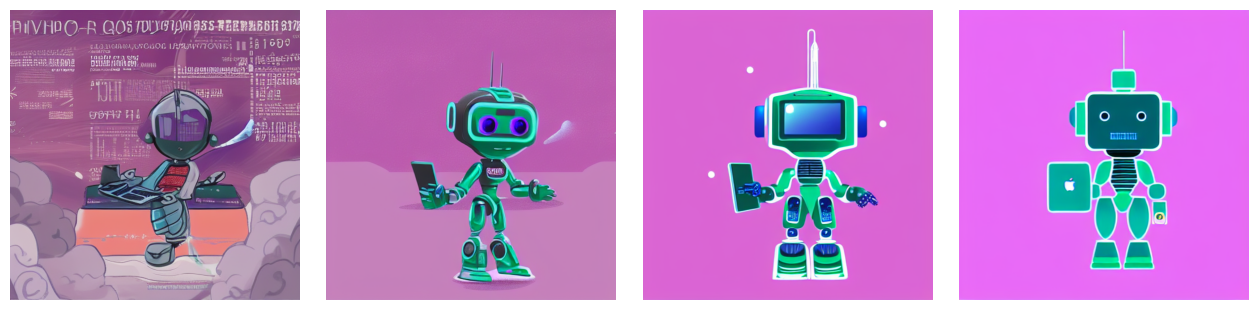

In [47]:
base_prompt = "a friendly robot mascot holding a laptop, simple falt illustraion, pastel colors, background is white"

show_images([draw(base_prompt, steps = s, seed = 1) for s in (2, 5, 10, 25)])
print("=" * 50)
show_images([draw(base_prompt, guidance = g, seed = 1) for g in (1, 4, 7.5, 15)])

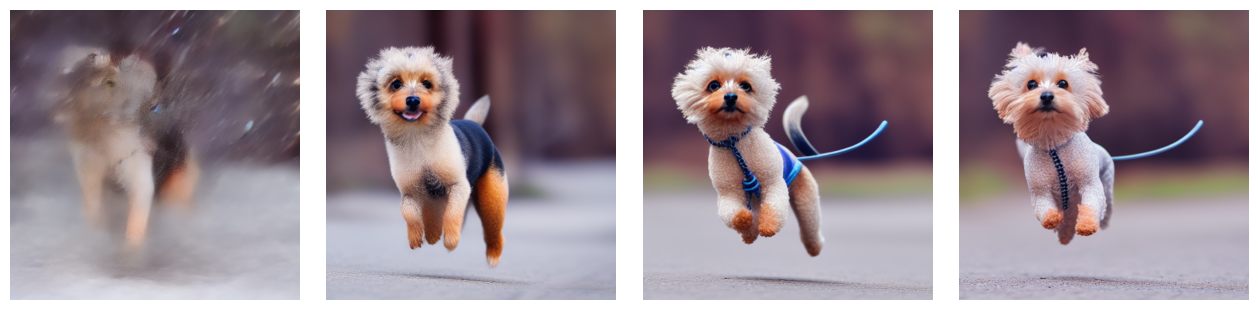

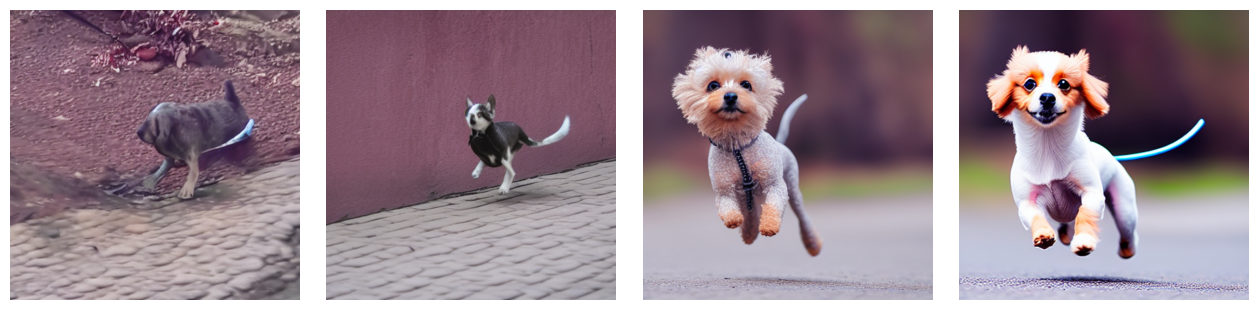

In [48]:
base_prompt = "a little dog who is running"

show_images([draw(base_prompt, steps = s, seed = 1) for s in (2, 5, 10, 25)])
print("=" * 50)
show_images([draw(base_prompt, guidance = g, seed = 1) for g in (1, 4, 7.5, 15)])